In [35]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

In [36]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
file = ("/content/drive/MyDrive/AQI Prediction Project/Dataset/city_day.csv")

In [38]:
df_raw = pd.read_csv(file)
df = df_raw.copy()
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset shape: (29531, 16)

Column names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [69]:
original_rows = len(df_raw)
original_columns = len(df_raw.columns)

In [40]:
# Data types and non-null counts
df.info()

# Missing values
missing = pd.DataFrame({"Missing_Count": df.isnull().sum(),
"Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

print(missing.sort_values("Missing_Percentage",ascending=False))

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Summary statistics
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB
            Missing_Count  Missing_Percentage
Xylene              18109               61.32
PM10    

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
City,29531,26,Ahmedabad,2009,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,29531,2009,2020-06-26,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PM2.5,24933.0,NaN,NaN,NaN,67.450578,64.661449,0.04,28.82,48.57,80.59,949.99
PM10,18391.0,NaN,NaN,NaN,118.127103,90.60511,0.01,56.255,95.68,149.745,1000.0
NO,25949.0,NaN,NaN,NaN,17.57473,22.785846,0.02,5.63,9.89,19.95,390.68
NO2,25946.0,NaN,NaN,NaN,28.560659,24.474746,0.01,11.75,21.69,37.62,362.21
NOx,25346.0,NaN,NaN,NaN,32.309123,31.646011,0.0,12.82,23.52,40.1275,467.63
NH3,19203.0,NaN,NaN,NaN,23.483476,25.684275,0.01,8.58,15.85,30.02,352.89
CO,27472.0,NaN,NaN,NaN,2.248598,6.962884,0.0,0.51,0.89,1.45,175.81
SO2,25677.0,NaN,NaN,NaN,14.531977,18.133775,0.01,5.67,9.16,15.22,193.86


In [41]:
# Standardize column names

In [42]:
df.columns = ( df.columns.str.strip().str.replace(" ", "_", regex=False))

print(df.columns.tolist())

['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


In [43]:
# Convert the date column

In [44]:
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(
        df["Date"],
        errors="coerce"
    )

    invalid_dates = df["Date"].isna().sum()

    print("Invalid or missing dates:", invalid_dates)
    print("Date range:", df["Date"].min(), "to", df["Date"].max())
else:
    print("Date column not found. Check the dataset schema.")

Invalid or missing dates: 0
Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00


In [45]:
# Check missing values

In [46]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2),
    "Data_Type": df.dtypes.astype(str)
})

missing_report = missing_report.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing_report)

missing_report.to_csv("/content/drive/MyDrive/AQI Prediction Project/"
                      "Dataset/missing_values_report.csv"
)

,Missing_Count,Missing_Percentage,Data_Type
Xylene,18109,61.32,float64
PM10,11140,37.72,float64
NH3,10328,34.97,float64
Toluene,8041,27.23,float64
Benzene,5623,19.04,float64
AQI,4681,15.85,float64
AQI_Bucket,4681,15.85,object
PM2.5,4598,15.57,float64
NOx,4185,14.17,float64
O3,4022,13.62,float64


In [47]:
# Visualize missing values

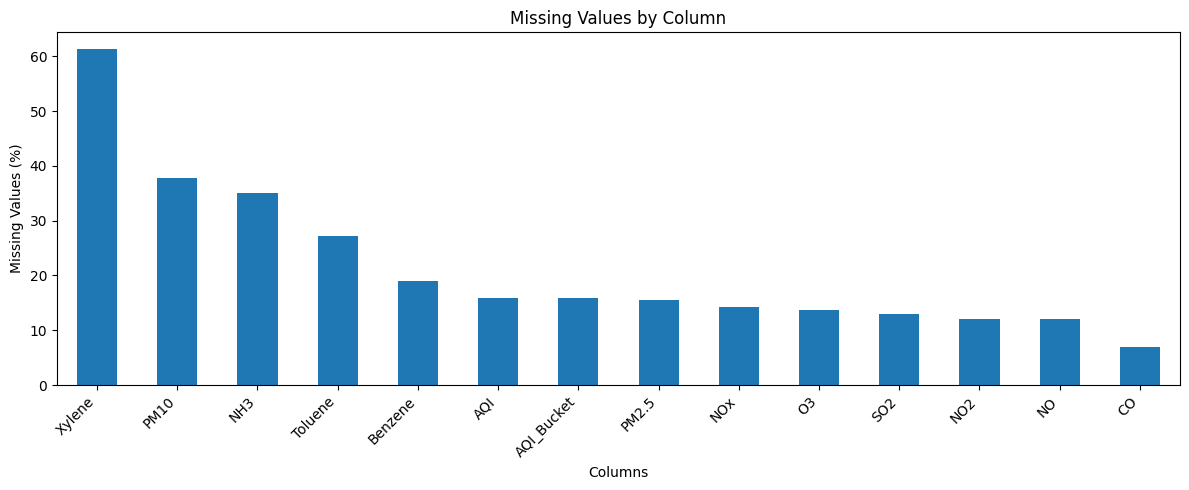

In [48]:
import matplotlib.pyplot as plt

missing_pct = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_pct = missing_pct[missing_pct > 0]

if len(missing_pct) > 0:
    plt.figure(figsize=(12, 5))
    missing_pct.plot(kind="bar")
    plt.title("Missing Values by Column")
    plt.ylabel("Missing Values (%)")
    plt.xlabel("Columns")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

In [49]:
# Identify exact duplicate records

In [50]:
exact_duplicates = df.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)

if exact_duplicates > 0:
    display(df[df.duplicated(keep=False)].head(10))

# Remove only exact duplicate records
df = df.drop_duplicates().copy()

print("Shape after removing exact duplicates:", df.shape)

Exact duplicate rows: 0
Shape after removing exact duplicates: (29531, 16)


In [51]:
# Convert numeric columns to numeric types

In [52]:
pollutant_candidates = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3",
    "Benzene", "Toluene", "Xylene"
]

numeric_candidates = pollutant_candidates + ["AQI"]

numeric_cols = [
    col for col in numeric_candidates
    if col in df.columns
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

print("Numeric columns converted:", numeric_cols)
display(df[numeric_cols].dtypes)

Numeric columns converted: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI']


,0
PM2.5,float64
PM10,float64
NO,float64
NO2,float64
NOx,float64
NH3,float64
CO,float64
SO2,float64
O3,float64
Benzene,float64


In [53]:
# Check physically invalid negative values

In [54]:
nonnegative_cols = [
    col for col in numeric_cols
    if col in df.columns
]

for col in nonnegative_cols:
    negative_count = (df[col] < 0).sum()
    print(f"{col}: {negative_count} negative values")

    df.loc[df[col] < 0, col] = np.nan

PM2.5: 0 negative values
PM10: 0 negative values
NO: 0 negative values
NO2: 0 negative values
NOx: 0 negative values
NH3: 0 negative values
CO: 0 negative values
SO2: 0 negative values
O3: 0 negative values
Benzene: 0 negative values
Toluene: 0 negative values
Xylene: 0 negative values
AQI: 0 negative values


In [55]:
# Check missing AQI targets

In [72]:
if "AQI" not in df.columns:
    raise ValueError(
        "AQI column is missing. "
        "Check the dataset and column names."
    )

print("Rows before target filtering:", len(df))
print("Missing AQI:", df["AQI"].isna().sum())

df = df.dropna(subset=["AQI"]).copy()

print("Rows after removing missing AQI:", len(df))

out_of_range_aqi = df[~df["AQI"].between(0, 500)]

print("AQI values outside 0–500:", len(out_of_range_aqi))
display(out_of_range_aqi[["City", "Date", "AQI"]].head(20))

Rows before target filtering: 24850
Missing AQI: 0
Rows after removing missing AQI: 24850
AQI values outside 0–500: 543


,City,Date,AQI
30,Ahmedabad,2015-01-31,514.0
31,Ahmedabad,2015-02-01,782.0
32,Ahmedabad,2015-02-02,914.0
33,Ahmedabad,2015-02-03,660.0
43,Ahmedabad,2015-02-13,510.0
44,Ahmedabad,2015-02-14,761.0
46,Ahmedabad,2015-02-16,536.0
48,Ahmedabad,2015-02-18,592.0
50,Ahmedabad,2015-02-20,588.0
51,Ahmedabad,2015-02-21,1141.0


In [57]:
# Investigate duplicate city-date combinations

In [58]:
if {"City", "Date"}.issubset(df.columns):

    duplicate_city_dates = df.duplicated(
        subset=["City", "Date"],
        keep=False
    )

    print(
        "Rows with repeated City-Date combinations:",
        duplicate_city_dates.sum()
    )

    display(
        df.loc[duplicate_city_dates]
        .sort_values(["City", "Date"])
        .head(20)
    )
else:
    print("City or Date column not found; skipping this check.")

Rows with repeated City-Date combinations: 0


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket


In [59]:
# Detect outliers using the IQR method

In [60]:
outlier_results = []

for col in numeric_cols:
    series = df[col].dropna()

    if series.empty:
        continue

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

    outlier_results.append({
        "Column": col,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": int(outlier_mask.sum()),
        "Outlier_Percentage": round(
            outlier_mask.mean() * 100, 2
        )
    })

outlier_report = pd.DataFrame(outlier_results)
display(outlier_report)

,Column,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,PM2.5,-48.88750,158.81250,1911,7.69
1,PM10,-83.33000,290.29000,1023,4.12
2,NO,-15.89500,41.58500,2342,9.42
3,NO2,-27.51000,77.69000,1072,4.31
4,NOx,-27.48000,80.76000,1652,6.65
5,NH3,-23.14000,62.46000,958,3.86
6,CO,-0.74500,2.81500,2289,9.21
7,SO2,-8.38500,29.25500,2409,9.69
8,O3,-20.99500,86.32500,664,2.67
9,Benzene,-4.43500,8.00500,1458,5.87


In [61]:
outlier_report.to_csv(
    "/content/drive/MyDrive/AQI Prediction Project/"
    "Dataset/outlier_report.csv",
    index=False
)

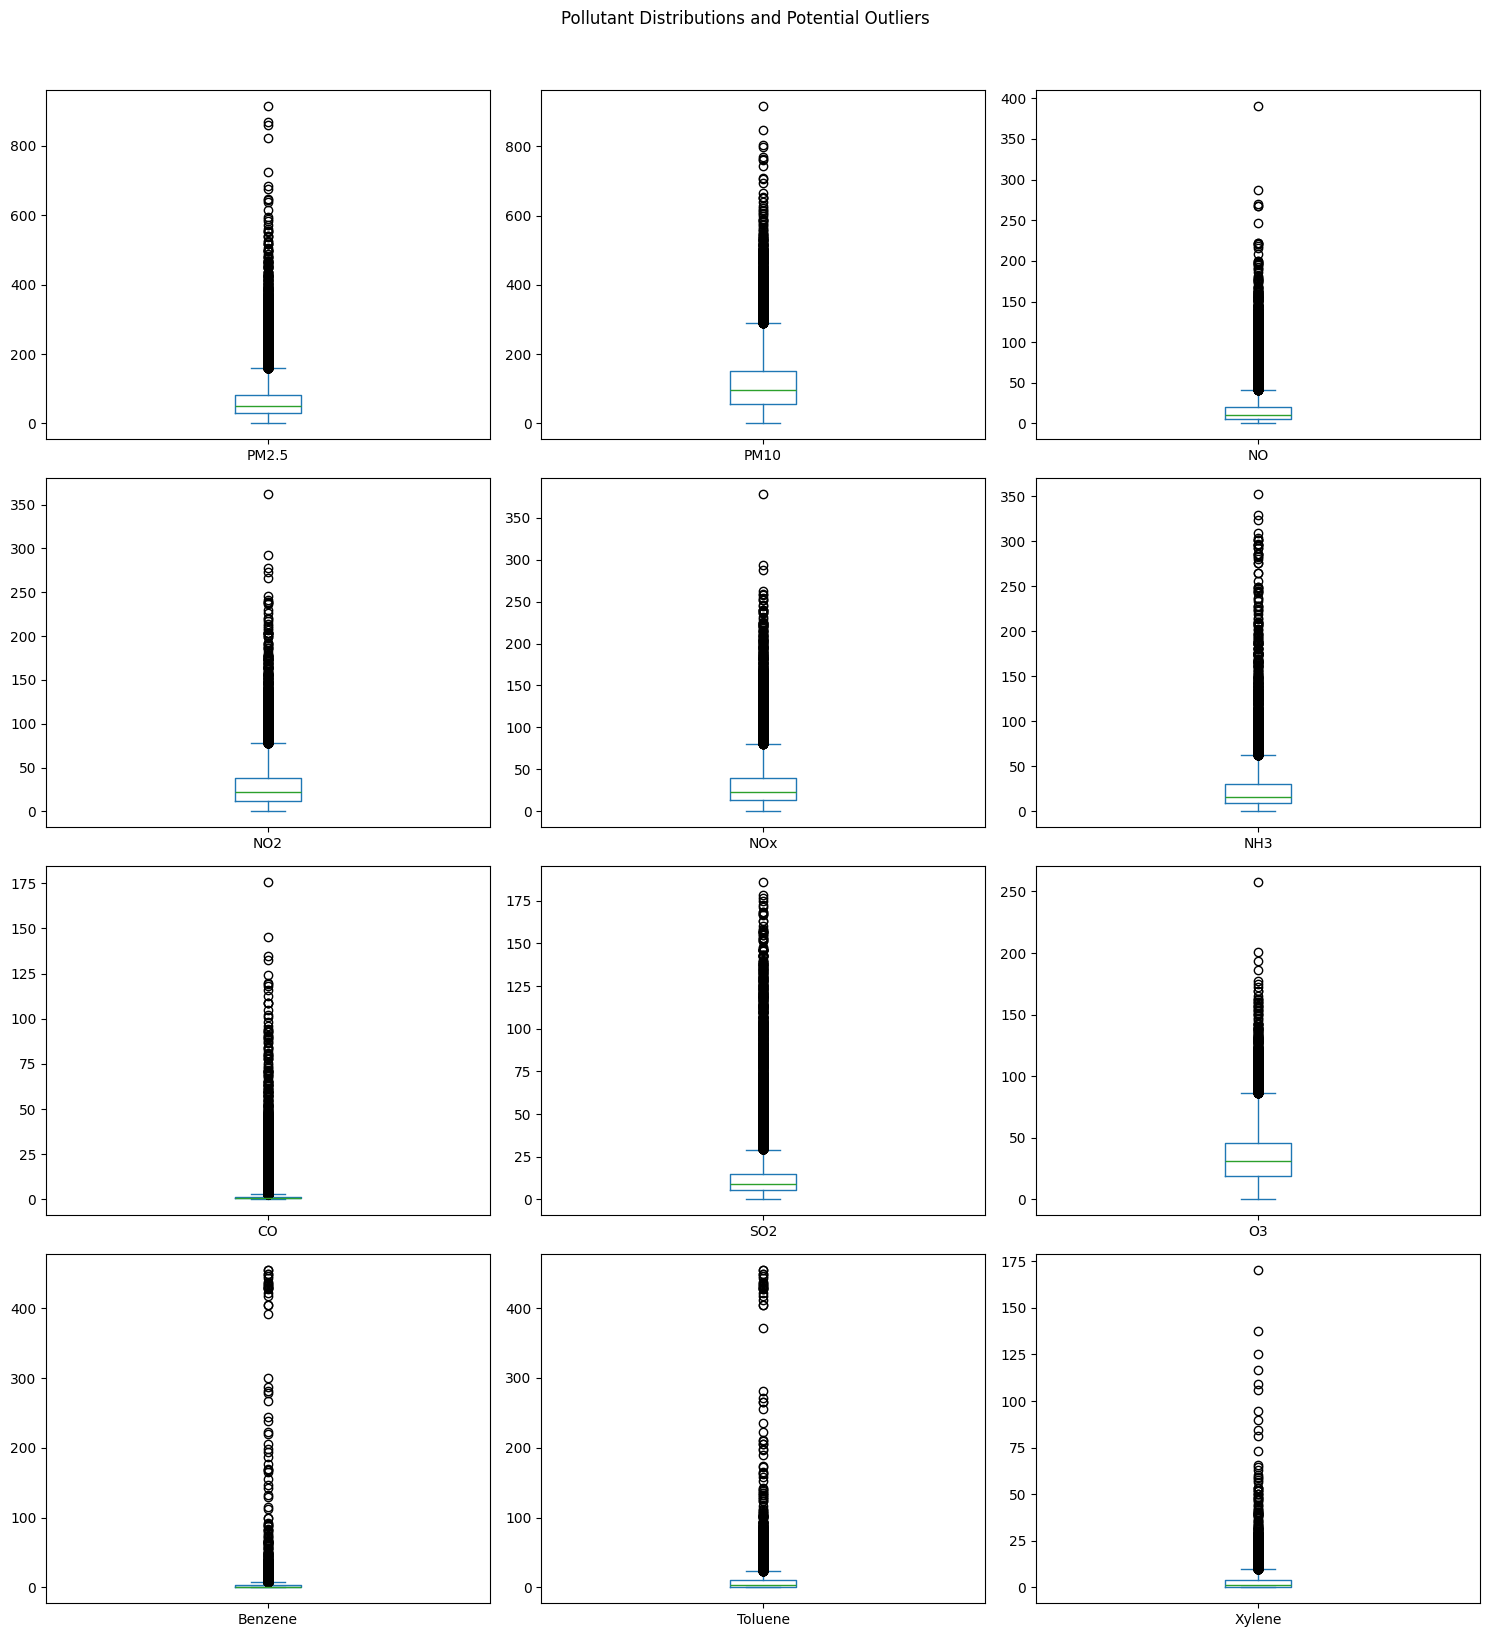

In [62]:
# Visualize pollutant outliers with box plots
available_pollutants = [
    col for col in pollutant_candidates
    if col in df.columns
]

if available_pollutants:
    df[available_pollutants].plot(
        kind="box",
        subplots=True,
        layout=(
            (len(available_pollutants) + 2) // 3,
            3
        ),
        figsize=(15, 4 * ((len(available_pollutants) + 2) // 3)),
        sharey=False
    )

    plt.suptitle(
        "Pollutant Distributions and Potential Outliers",
        y=1.02
    )
    plt.tight_layout()
    plt.show()
else:
    print("No pollutant columns found.")

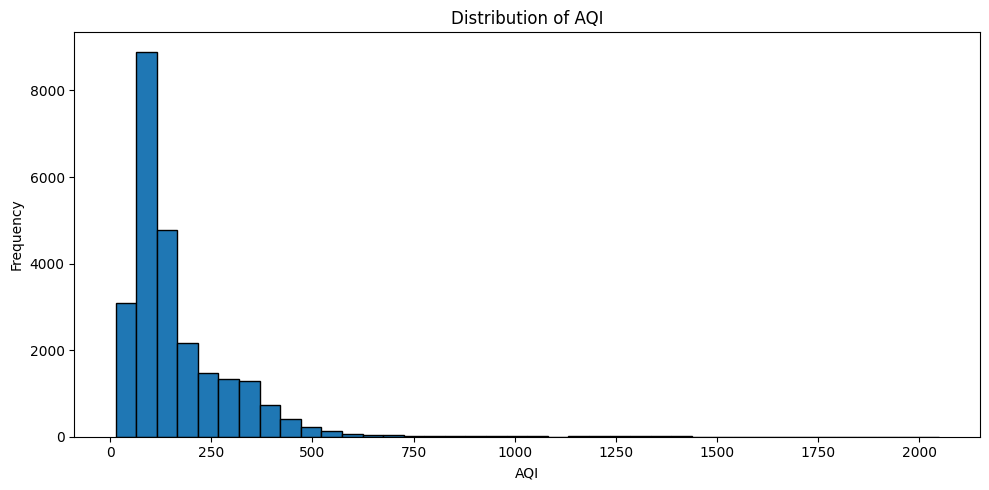

count    24850.000000
mean       166.463581
std        140.696585
min         13.000000
25%         81.000000
50%        118.000000
75%        208.000000
max       2049.000000
Name: AQI, dtype: float64


In [63]:
# Examine AQI distribution
plt.figure(figsize=(10, 5))

plt.hist(
    df["AQI"].dropna(),
    bins=40,
    edgecolor="black"
)

plt.title("Distribution of AQI")
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(df["AQI"].describe())

Missing AQI categories: 0


,AQI_Category,Count
0,Moderate,8829
1,Satisfactory,8224
2,Poor,2781
3,Very Poor,2337
4,Good,1341
5,Severe,1338


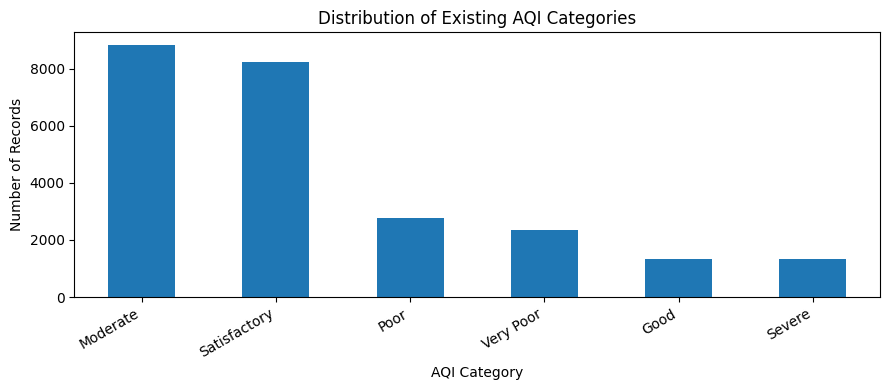

In [64]:
# Check the existing AQI categories
if "AQI_Bucket" in df.columns:

    print("Missing AQI categories:",
          df["AQI_Bucket"].isna().sum())

    display(
        df["AQI_Bucket"]
        .value_counts(dropna=False)
        .rename_axis("AQI_Category")
        .reset_index(name="Count")
    )

    df["AQI_Bucket"].value_counts().plot(
        kind="bar",
        figsize=(9, 4)
    )

    plt.title("Distribution of Existing AQI Categories")
    plt.xlabel("AQI Category")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("AQI_Bucket is not present.")

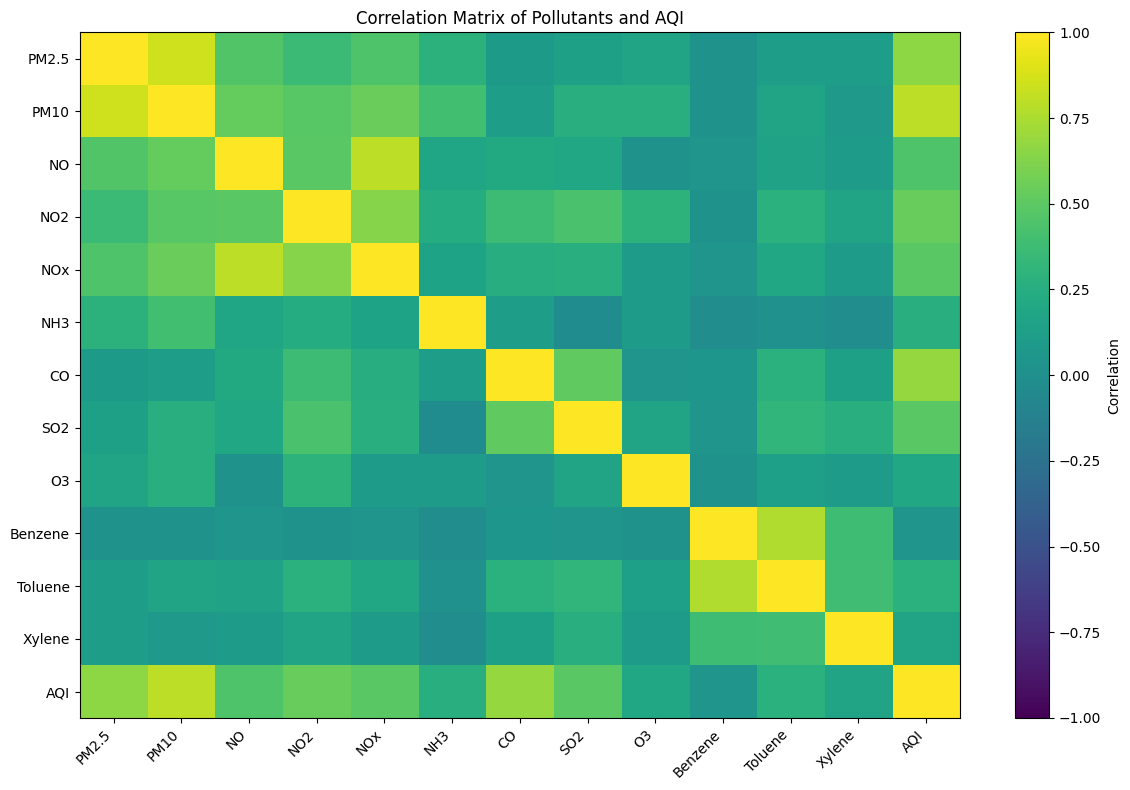

In [65]:
# Check correlations between numerical features
corr_cols = [
    col for col in numeric_cols
    if col in df.columns
]

corr = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(12, 8))

plt.imshow(
    corr,
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")
plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(corr.index)),
    corr.index
)

plt.title("Correlation Matrix of Pollutants and AQI")
plt.tight_layout()
plt.show()

In [70]:
candidate_features = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"
]

features = candidate_features.copy()
target = "AQI"

missing_features = [
    col for col in features + [target]
    if col not in df.columns
]

if missing_features:
    raise ValueError(f"Missing required columns: {missing_features}")

print("Target:", target)
print("Features:", features)
print("Number of features:", len(features))

Target: AQI
Features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
Number of features: 12


In [71]:
final_rows = len(df)

cleaning_summary = pd.DataFrame({
    "Metric": [
        "Original rows",
        "Final rows",
        "Rows removed",
        "Original columns",
        "Final columns",
        "Remaining missing cells",
        "Rows with missing pollutant values"
    ],
    "Value": [
        original_rows,
        final_rows,
        original_rows - final_rows,
        original_columns,
        len(df.columns),
        int(df.isna().sum().sum()),
        int(df[features].isna().any(axis=1).sum())
    ]
})

display(cleaning_summary)

,Metric,Value
0,Original rows,29531
1,Final rows,24850
2,Rows removed,4681
3,Original columns,16
4,Final columns,16
5,Remaining missing cells,43525
6,Rows with missing pollutant values,18614


In [68]:
output_dir = (
    "/content/drive/MyDrive/"
    "AQI Prediction Project/Dataset"
)

os.makedirs(output_dir, exist_ok=True)

cleaned_path = os.path.join(
    output_dir,
    "city_day_cleaned.csv"
)

df.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved to:")
print(cleaned_path)

print("Final dataset shape:", df.shape)
print("Missing AQI targets:", df["AQI"].isna().sum())
print("Remaining missing predictor values:",
      df[features].isna().sum().to_dict())

Cleaned dataset saved to:
/content/drive/MyDrive/AQI Prediction Project/Dataset/city_day_cleaned.csv
Final dataset shape: (24850, 16)
Missing AQI targets: 0
Remaining missing predictor values: {'PM2.5': 678, 'PM10': 7086, 'NO2': 391, 'SO2': 605, 'CO': 445, 'O3': 807}
